# Data cleaning & exploratory analysis

**Goal:** turn the raw South African station exports into clean 15-minute training windows that match the
`Test.csv` format, and see how the test windows differ from the real backgrounds.

**Inputs**
- `South_African_Real_Acoustics/acoustics/*.parquet`: unlabelled real backgrounds, one row per minute (≈1.7M rows)
- `Test.csv`: 1,500 windows × (15 minutes × 25 bands), each a real background with a controlled vessel passage added

**Outputs** (written to `data_clean/`, which git ignores)
- `minutes_clean.parquet`: cleaned minute-level table (25 common bands plus metadata and QC flags)
- `windows_15min.parquet`: non-overlapping 15-minute windows in the same wide layout as `Test.csv`, plus metadata

Run the cells top to bottom. Loading everything takes about 1 minute and roughly 1 GB of RAM.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

DATA_DIR = Path(".")
RAW_DIR = DATA_DIR / "South_African_Real_Acoustics"
OUT_DIR = DATA_DIR / "data_clean"
OUT_DIR.mkdir(exist_ok=True)

BANDS = ["31.6", "39.8", "50.1", "63.1", "79.4", "100", "125.9", "158.5", "199.5", "251.2",
         "316.2", "398.1", "501.2", "631", "794.3", "1000", "1258.9", "1584.9", "1995.3",
         "2511.9", "3162.3", "3981.1", "5011.9", "6309.6", "7943.3"]
TOL = [f"TOL_{b}" for b in BANDS]
FREQ = np.array([float(b) for b in BANDS])
N_MIN, N_BAND = 15, 25

def db_to_lin(x):
    return 10.0 ** (np.asarray(x, dtype=np.float64) / 10.0)

def lin_to_db(x):
    return 10.0 * np.log10(x)

def broadband_db(levels_db, axis=-1):
    """Energy sum across bands (dB -> linear -> sum -> dB). NaN if any band is missing."""
    return lin_to_db(db_to_lin(levels_db).sum(axis=axis))

# Plot style: thin marks, recessive grid, fixed categorical order.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GRAY = "#9a9994"
mpl.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "xtick.color": "#52514e", "ytick.color": "#52514e",
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 8.5,
    "axes.prop_cycle": mpl.cycler(color=SERIES),
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

def freq_axis(ax):
    ax.set_xscale("log")
    ax.set_xticks([31.6, 100, 316.2, 1000, 3162.3, 7943.3])
    ax.set_xticklabels(["31.6", "100", "316", "1k", "3.2k", "7.9k"])
    ax.set_xlabel("Band centre (Hz)")

## 1. Load the station files

Only the 25 common bands (31.6 Hz to 7.9 kHz) appear in the test set, so the other 37 export bands are dropped.
A **deployment** is one recorder at one site. Several recorders were moved between sites (for example recorder
`8230` was at Riy Banks and later Durban), so `site + recorder` is the right unit for grouping and for
cross-validation splits.

In [2]:
META = ["site", "recorder", "sample_rate_hz", "t", "dur",
        "qc_duration_ge55", "qc_25band_finite", "qc_25band_spread_ge6"]

frames = []
for f in sorted((RAW_DIR / "acoustics").glob("*.parquet")):
    frames.append(pd.read_parquet(f, columns=META + TOL))
raw = pd.concat(frames, ignore_index=True)
del frames

raw["site_id"] = raw["site"].str.extract(r"^(\d+)")[0].astype(int)
raw["site_name"] = raw["site"].str.replace(r"^\d+\s*", "", regex=True).str.replace("_", " ")
raw["deployment"] = raw["site_id"].astype(str).str.zfill(2) + "|" + raw["recorder"]

print(f"{len(raw):,} rows, {raw['site_id'].nunique()} sites, "
      f"{raw['recorder'].nunique()} recorders, {raw['deployment'].nunique()} deployments")
print("Memory:", round(raw.memory_usage(deep=True).sum() / 1e9, 2), "GB")

1,715,779 rows, 10 sites, 12 recorders, 17 deployments
Memory: 0.43 GB


In [3]:
stations = pd.read_csv(RAW_DIR / "stations.csv")
summary = (raw.groupby(["site_id", "site_name"])
              .agg(rows=("t", "size"), recorders=("recorder", "nunique"),
                   first=("t", "min"), last=("t", "max"),
                   sample_rates=("sample_rate_hz", lambda s: sorted(s.unique().tolist())))
              .reset_index())
assert summary["rows"].sum() == stations["minutes"].sum()  # matches the published counts
summary

,site_id,site_name,rows,recorders,first,last,sample_rates
0,1,Richards Bay,1001174,3,2017-05-09 00:00:02,2024-05-25 23:59:00,[24000]
1,2,Durban,44640,1,2025-10-28 00:00:00,2025-12-06 23:59:00,[48000]
2,3,Cape Recife,5928,1,2024-03-05 00:00:00,2024-03-23 23:12:00,[48000]
3,4,Bird Island,47552,2,2022-03-21 05:59:58,2024-06-29 23:59:00,"[12000, 24000]"
4,5,St Croix Island,250717,3,2022-04-05 00:00:00,2025-09-20 06:00:00,"[12000, 24000]"
5,6,Riy Banks,4121,1,2024-03-05 00:00:00,2024-04-05 23:12:00,[48000]
6,7,St Francis,169488,1,2015-04-21 00:00:00,2018-02-28 14:24:00,[48000]
7,9,Fish Hoek,53767,2,2016-09-13 00:00:02,2021-09-28 12:45:00,[96000]
8,10,Sea Point,3660,1,2018-10-11 10:00:02,2018-10-13 23:59:00,[96000]
9,13,Saldhana Bay,134732,2,2022-03-22 00:00:00,2023-05-29 04:34:00,"[48000, 96000]"


## 2. Data-quality audit

Checks for the problems the data dictionary warns about: gaps, durations, sentinel values, recorder changes,
plus a few found while exploring.

In [4]:
levels = raw[TOL].to_numpy(np.float32, copy=True)

audit = pd.DataFrame({
    "missing cells (25 bands)": int(np.isnan(levels).sum()),
    "rows sorted by time within file order": bool(raw["t"].is_monotonic_increasing),
    "duplicate (recorder, t) rows": int(raw.duplicated(["recorder", "t"]).sum()),
    "dur != 60 s": int((raw["dur"] != 60).sum()),
    "dur < 55 s": int((raw["dur"] < 55).sum()),
    "cells < 0 dB": int((levels < 0).sum()),
    "cells == -156.5 dB": int((levels == -156.5).sum()),
    "rows failing qc_25band_spread_ge6": int((~raw["qc_25band_spread_ge6"]).sum()),
}, index=["value"]).T
audit

,value
missing cells (25 bands),0
rows sorted by time within file order,False
"duplicate (recorder, t) rows",0
dur != 60 s,36234
dur < 55 s,16896
cells < 0 dB,16335
cells == -156.5 dB,16325
rows failing qc_25band_spread_ge6,4974


### 2a. Sentinel values

Richards Bay has **16,325 cells at exactly −156.5 dB**, a fill value and not a measurement (every other site's
minimum is above 20 dB). There are also four isolated small negative values. Both are set to NaN below.

In [5]:
neg = levels < 0
by_site = pd.Series(neg.any(axis=1)).groupby(raw["site_name"].values).sum()
print("Rows containing a negative band level, by site:")
print(by_site[by_site > 0])

rows_neg = neg.any(axis=1)
print("\nNumber of bands affected per sentinel row:",
      pd.Series(neg[rows_neg].sum(axis=1)).value_counts().sort_index().to_dict())

Rows containing a negative band level, by site:
Richards Bay    654
dtype: int64

Number of bands affected per sentinel row: {10: 1, 25: 653}


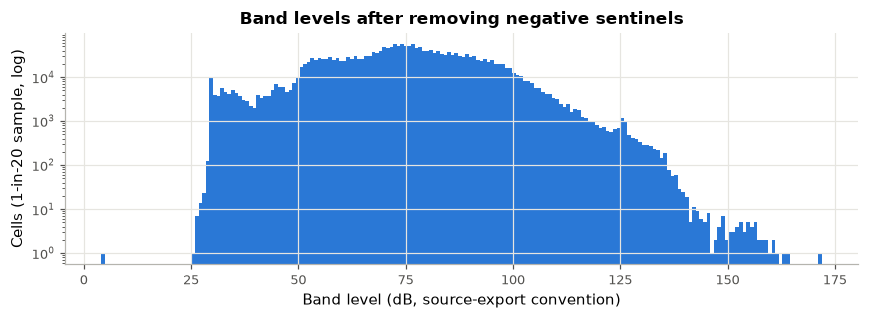

Percentiles 0.01 / 1 / 50 / 99 / 99.99: [ 29.1  31.1  73.4 109.3 135.4]


In [6]:
fig, ax = plt.subplots(figsize=(8, 3))
v = levels[~neg].ravel()
ax.hist(v[::20], bins=200, color=SERIES[0], edgecolor="none")
ax.set_yscale("log")
ax.set_xlabel("Band level (dB, source-export convention)")
ax.set_ylabel("Cells (1-in-20 sample, log)")
ax.set_title("Band levels after removing negative sentinels")
plt.tight_layout(); plt.show()
print("Percentiles 0.01 / 1 / 50 / 99 / 99.99:", np.round(np.percentile(v, [0.01, 1, 50, 99, 99.99]), 1))

### 2b. Frozen rows

Some rows repeat the previous minute's 25-band vector exactly, which is very unlikely for real ambient noise
quantised to 0.1 dB and points to a stuck export. Checking the raw values, **before** the sentinels are
removed, shows that every frozen row is a sentinel row (a run of −156.5 values). Apart from the sentinel
rows there are no stuck exports. The flag is kept as a safeguard for future data.

In [7]:
raw = raw.sort_values(["deployment", "t"], kind="stable").reset_index(drop=True)
levels = raw[TOL].to_numpy(np.float32, copy=True)

same_dep = raw["deployment"].values[1:] == raw["deployment"].values[:-1]
identical = np.zeros(len(raw), bool)
identical[1:] = same_dep & np.all(levels[1:] == levels[:-1], axis=1)
is_sentinel = (levels < 0).any(axis=1)
print("Frozen rows (raw values):", int(identical.sum()),
      "| of which sentinel rows:", int((identical & is_sentinel).sum()))

levels[levels < 0] = np.nan
raw["flag_sentinel"] = is_sentinel
raw["flag_frozen"] = identical & ~is_sentinel

Frozen rows (raw values): 649 | of which sentinel rows: 649


### 2c. Durations and timestamp spacing

The test windows are 15 *consecutive* complete minutes, so a training window must not straddle a gap or a short
minute. The spacing check allows ±10 s because some exports start at `:02` or `:58`.

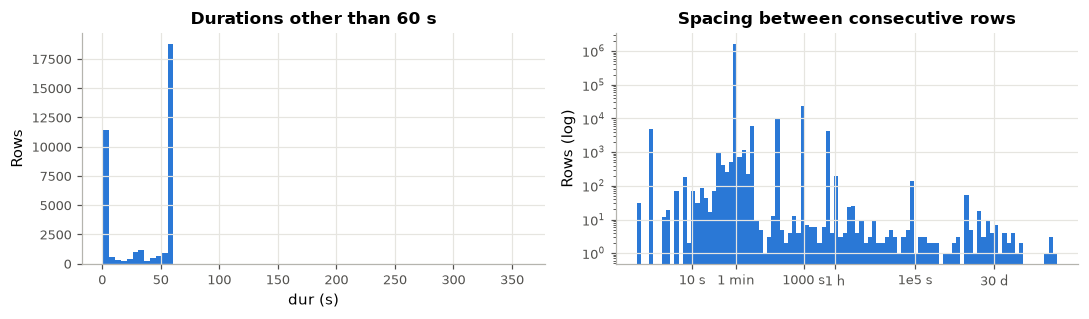

Spacing within 50-70 s: 96.9%
Gaps > 2 min, per site:
site_name
St Francis         27153
Fish Hoek           9750
Cape Recife          455
Riy Banks            316
Richards Bay         304
Saldhana Bay         186
St Croix Island      130
Bird Island           34
Durban                 1
Sea Point              1
Name: t, dtype: int64


In [8]:
dt = raw.groupby("deployment")["t"].diff().dt.total_seconds()
raw["gap_before_s"] = dt

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
d = raw["dur"]
axes[0].hist(d[d != 60], bins=72, color=SERIES[0], edgecolor="none")
axes[0].set_title("Durations other than 60 s")
axes[0].set_xlabel("dur (s)"); axes[0].set_ylabel("Rows")

g = dt.dropna()
axes[1].hist(np.log10(g[g > 0]), bins=100, color=SERIES[0], edgecolor="none")
axes[1].set_yscale("log")
axes[1].set_xticks([1, np.log10(60), 3, np.log10(3600), 5, np.log10(86400 * 30)])
axes[1].set_xticklabels(["10 s", "1 min", "1000 s", "1 h", "1e5 s", "30 d"])
axes[1].set_title("Spacing between consecutive rows")
axes[1].set_ylabel("Rows (log)")
plt.tight_layout(); plt.show()

print("Spacing within 50-70 s:", f"{dt.between(50, 70).mean():.1%}")
print("Gaps > 2 min, per site:")
print((dt > 120).groupby(raw["site_name"]).sum().sort_values(ascending=False))

#### Duty cycling

Several sites didn't record continuously. The table gives, for each site, the length of the contiguous runs
(consecutive minutes 50–70 s apart) and the most common gap length. **Cape Recife and Riy Banks record 13
minutes per cycle, and St Francis and Fish Hoek mostly record 5-minute bursts.** None of these can provide a
15-consecutive-minute window like the test layout.

In [9]:
brk = (~dt.between(50, 70)).values | np.r_[True, raw["deployment"].values[1:] != raw["deployment"].values[:-1]]
runs = pd.DataFrame({"site": raw["site_name"].values, "run": np.cumsum(brk)})
run_len = runs.groupby(["site", "run"]).size()
duty = run_len.groupby("site").agg(
    median_run_min="median",
    p90_run_min=lambda s: s.quantile(0.9),
    share_of_minutes_in_runs_ge15=lambda s: round(s[s >= 15].sum() / s.sum(), 3))
duty["most_common_gap_s"] = dt[dt > 70].groupby(raw["site_name"]).agg(lambda s: s.round().mode().iloc[0])
duty.sort_values("share_of_minutes_in_runs_ge15")

,median_run_min,p90_run_min,share_of_minutes_in_runs_ge15,most_common_gap_s
site,,,,
Cape Recife,13.0,13.0,0.000,2880.0
Riy Banks,13.0,13.0,0.000,2880.0
Fish Hoek,5.0,5.0,0.084,362.0
St Francis,5.0,15.0,0.298,960.0
Richards Bay,59.0,59.0,0.993,118.0
Bird Island,360.0,1440.0,0.999,86458.0
Durban,22320.0,34416.0,1.000,777660.0
Saldhana Bay,240.0,1079.0,1.000,3660.0
Sea Point,1830.0,3006.0,1.000,3660.0


### 2d. Coverage over time

Each bar marks a month with data for that deployment. The recordings span 2015 to 2025 and are very uneven:
Richards Bay alone accounts for **58%** of all minutes. A model trained on everything without reweighting
would mostly learn Richards Bay.

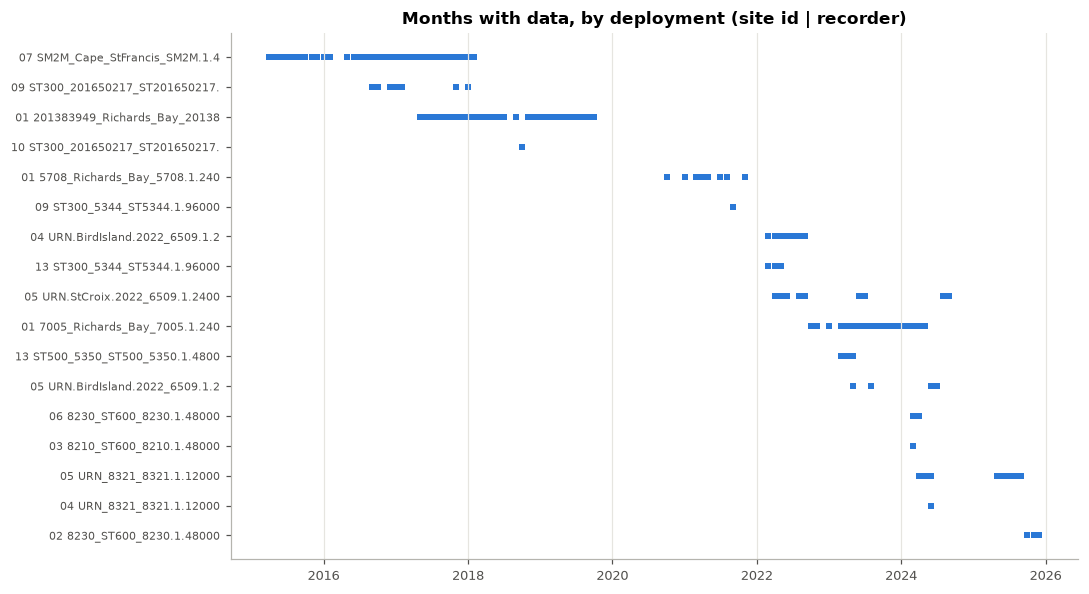

Share of minutes by site (%):
site_name
Richards Bay       58.4
St Croix Island    14.6
St Francis          9.9
Saldhana Bay        7.9
Fish Hoek           3.1
Bird Island         2.8
Durban              2.6
Cape Recife         0.3
Riy Banks           0.2
Sea Point           0.2
Name: proportion, dtype: float64


In [10]:
month = raw["t"].dt.to_period("M")
cov = raw.groupby(["deployment", month]).size().rename("n").reset_index()
deps = (raw.groupby("deployment")["t"].min().sort_values().index.tolist())

fig, ax = plt.subplots(figsize=(10, 5.5))
for i, dep in enumerate(deps):
    m = cov.loc[cov["deployment"] == dep, "t"].dt.to_timestamp()
    ax.scatter(m, np.full(len(m), i), marker="s", s=14, color=SERIES[0], linewidths=0)
ax.set_yticks(range(len(deps)))
ax.set_yticklabels([d.split("|")[0] + " " + d.split("|")[1][:28] for d in deps], fontsize=7.5)
ax.invert_yaxis()
ax.set_title("Months with data, by deployment (site id | recorder)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

share = raw["site_name"].value_counts(normalize=True).mul(100).round(1)
print("Share of minutes by site (%):"); print(share)

### 2e. 12 kHz recorder and the top two bands

Recorder `URN_8321` is tagged with a sample rate of 12000 Hz, so its Nyquist frequency is 6 kHz. Yet the 6.3 kHz
and 7.9 kHz bands hold finite values. The README says this is unresolved. The plot compares that recorder's
spectrum with a 24 kHz recorder at the same site.

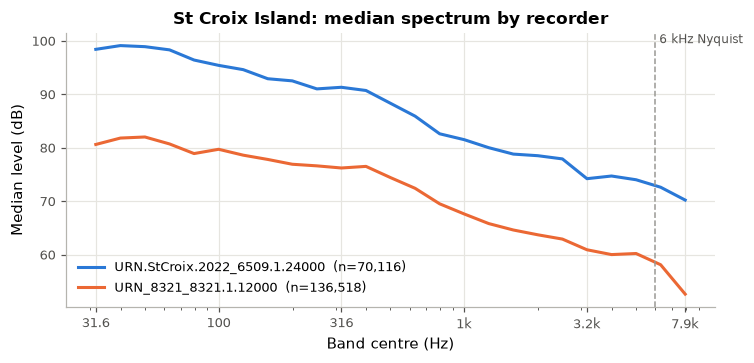

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for color, rec in [(SERIES[0], "URN.StCroix.2022_6509.1.24000"), (SERIES[1], "URN_8321_8321.1.12000")]:
    sel = (raw["recorder"] == rec).values
    med = np.nanmedian(levels[sel], axis=0)
    ax.plot(FREQ, med, color=color, label=f"{rec}  (n={sel.sum():,})")
ax.axvline(6000, color=GRAY, lw=1, ls="--")
ax.text(6000, ax.get_ylim()[1], " 6 kHz Nyquist", va="top", fontsize=8, color="#52514e")
freq_axis(ax); ax.set_ylabel("Median level (dB)")
ax.set_title("St Croix Island: median spectrum by recorder")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

**Decision:** the values above 6 kHz are **kept but flagged** (`flag_above_nyquist`). The test set has no
band-level gaps, so it is unclear whether such backgrounds appear in it. Excluding these windows from
training is a choice to test in experiments.

## 3. Cleaning

| Step | Rule | Why |
|---|---|---|
| Sort | by `deployment`, then `t` | Raw files are not in time order across recorders |
| Sentinels | level < 0 dB → NaN | −156.5 is a fill value; other negative values are isolated and implausible |
| Frozen rows | exact repeat of the previous minute → NaN | stuck export (none found apart from sentinel rows) |
| Short minutes | `dur` < 55 s → excluded from windows | not a full-minute average |
| Above Nyquist | flag only | unresolved and documented by the data owner |
| Low spread | `qc_25band_spread_ge6` false → flag only | a screening hint, not a definite error |

Values are never imputed in the minute-level table. Missing means missing, as the data dictionary requires.

In [12]:
levels[raw["flag_frozen"].values] = np.nan
raw[TOL] = levels

raw["flag_short"] = raw["dur"] < 55
raw["flag_above_nyquist"] = raw["sample_rate_hz"] < 2 * FREQ[-1]
raw["flag_low_spread"] = ~raw["qc_25band_spread_ge6"]
raw["row_ok"] = ~raw["flag_short"] & np.isfinite(levels).all(axis=1)

clean = raw.drop(columns=["qc_duration_ge55", "qc_25band_finite", "qc_25band_spread_ge6"])
clean.to_parquet(OUT_DIR / "minutes_clean.parquet", index=False)

flags = clean[["flag_sentinel", "flag_frozen", "flag_short", "flag_above_nyquist", "flag_low_spread"]].sum()
print(flags.to_string())
print(f"\nUsable minutes: {clean['row_ok'].sum():,} of {len(clean):,} ({clean['row_ok'].mean():.1%})")

flag_sentinel            654
flag_frozen                0
flag_short             16896
flag_above_nyquist    136518
flag_low_spread         4974

Usable minutes: 1,698,246 of 1,715,779 (99.0%)


## 4. Build 15-minute windows in the test layout

A window is 15 consecutive usable minutes from one deployment, with each step 50–70 s after the previous one.
Windows don't overlap. Column names match `Test.csv` (`m01_TOL_31.6` … `m15_TOL_7943.3`), so the same feature
code can run on both.

In [13]:
def make_windows(df, lv, n=N_MIN):
    ok = df["row_ok"].values
    step_ok = df["gap_before_s"].between(50, 70).values
    dep = df["deployment"].values
    # A run breaks when a row is unusable, the deployment changes, or the time step is off.
    start_new = ~ok | ~step_ok | np.r_[True, dep[1:] != dep[:-1]]
    run_id = np.cumsum(start_new)
    run_id[~ok] = -1
    starts = []
    for rid, idx in pd.Series(np.arange(len(df))[ok]).groupby(run_id[ok]):
        idx = idx.values
        for k in range(0, len(idx) - n + 1, n):
            starts.append(idx[k])
    starts = np.array(starts)
    X = np.stack([lv[s:s + n] for s in starts])            # (windows, 15, 25)
    meta = df.iloc[starts][["deployment", "site_id", "site_name", "recorder", "sample_rate_hz", "t"]]
    meta = meta.rename(columns={"t": "t_start"}).reset_index(drop=True)
    meta["any_above_nyquist"] = df["flag_above_nyquist"].values[starts]
    meta["any_low_spread"] = [df["flag_low_spread"].values[s:s + n].any() for s in starts]
    return X, meta

X_train, win_meta = make_windows(clean, levels)
wide_cols = [f"m{m:02d}_{c}" for m in range(1, N_MIN + 1) for c in TOL]
windows = pd.concat([win_meta, pd.DataFrame(X_train.reshape(len(X_train), -1), columns=wide_cols)], axis=1)
windows.insert(0, "window_id", np.arange(len(windows)))
windows.to_parquet(OUT_DIR / "windows_15min.parquet", index=False)

print("Windows:", X_train.shape)
per_site = win_meta["site_name"].value_counts().reindex(sorted(clean["site_name"].unique())).fillna(0).astype(int)
print(per_site.sort_values(ascending=False).to_string())

Windows: (88119, 15, 25)
site_name
Richards Bay       52494
St Croix Island    16701
Saldhana Bay        8868
St Francis          3371
Bird Island         3168
Durban              2976
Fish Hoek            297
Sea Point            244
Cape Recife            0
Riy Banks              0


Because of duty cycling, **Cape Recife and Riy Banks produce no windows**, and St Francis and Fish Hoek produce
very few. If those sites matter (section 6a suggests St Francis may), one option is to build windows from
shorter runs and blank the missing minutes. That departs from the test layout, where at most 3 minutes are
missing, so treat it as an experiment.

## 5. Test set: shape and missingness

Missing values in the test set **always cover whole minutes**. There are no isolated missing cells and no band
missing across a whole window. 717 windows miss one minute and 8 miss two or three. The missing minute is nearly
always the first (42% of windows) or the last (7%), which suggests the windows were cut from timelines that
sometimes ended a minute short.

Windows with any missing cell: 48.3%
Missing cells per window: {0: 775, 25: 717, 50: 7, 75: 1}
Whole-minute gaps: 734 | partial-minute gaps: 0


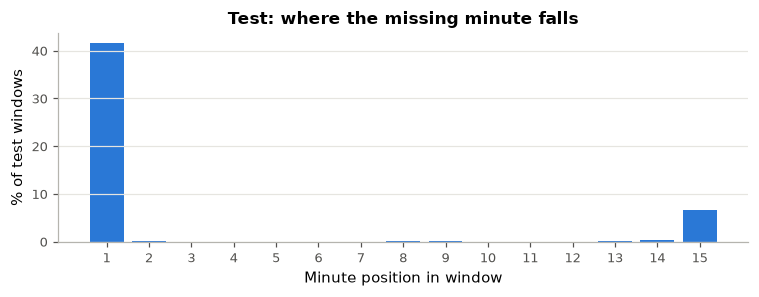

In [14]:
test = pd.read_csv(DATA_DIR / "Test.csv", dtype={"ID": str})
feat = [c for c in test.columns if c != "ID"]
assert feat == wide_cols  # identical layout to our windows
X_test = test[feat].to_numpy(np.float32, copy=True).reshape(-1, N_MIN, N_BAND)
miss = np.isnan(X_test)

print("Windows with any missing cell:", f"{miss.any(axis=(1, 2)).mean():.1%}")
print("Missing cells per window:", pd.Series(miss.sum(axis=(1, 2))).value_counts().to_dict())
print("Whole-minute gaps:", int(miss.all(axis=2).sum()), "| partial-minute gaps:",
      int((miss.any(axis=2) & ~miss.all(axis=2)).sum()))

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(np.arange(1, 16), miss.all(axis=2).mean(axis=0) * 100, color=SERIES[0], width=0.8)
ax.set_xticks(range(1, 16)); ax.set_xlabel("Minute position in window")
ax.set_ylabel("% of test windows")
ax.set_title("Test: where the missing minute falls")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Implication:** when building training examples, blank one whole minute (mostly minute 1, sometimes minute 15)
at about the same rates, so the model sees the same missingness pattern. Missing minutes should stay NaN, or be
handled in features with NaN-aware statistics, rather than being filled with zero.

## 6. Spectra: training stations vs test

Median spectrum per station (blue) with its 10–90% range shaded. The gray line in every panel is the test
median for comparison. Percentiles are computed on dB values, which is fine for describing distributions.
For **averages**, convert to linear energy first.

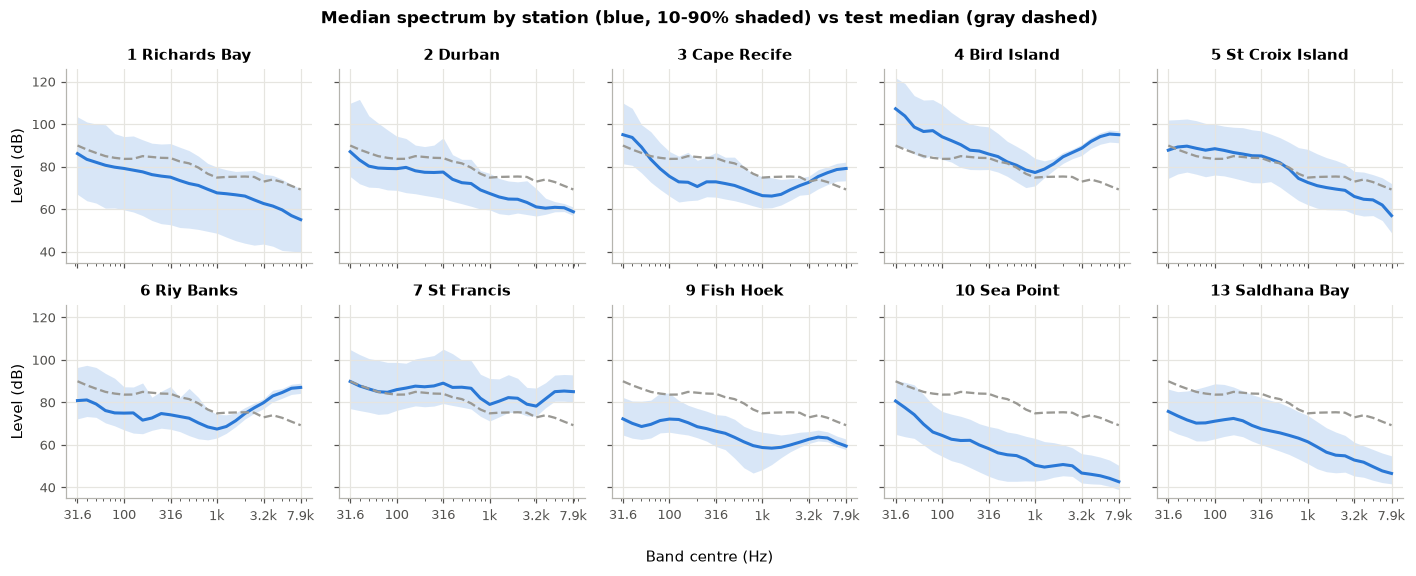

In [15]:
rng = np.random.default_rng(0)
site_order = clean.groupby("site_id")["site_name"].first()
test_med = np.nanmedian(X_test.reshape(-1, N_BAND), axis=0)
site_ids = clean["site_id"].values
ok_rows = clean["row_ok"].values

fig, axes = plt.subplots(2, 5, figsize=(13, 5.2), sharex=True, sharey=True)
for ax, (sid, name) in zip(axes.ravel(), site_order.items()):
    sel = np.where((site_ids == sid) & ok_rows)[0]          # all usable minutes, incl. duty-cycled sites
    sel = rng.choice(sel, min(len(sel), 50000), replace=False)
    s = levels[sel]
    p10, p50, p90 = np.nanpercentile(s, [10, 50, 90], axis=0)
    ax.fill_between(FREQ, p10, p90, color=SERIES[0], alpha=0.18, linewidth=0)
    ax.plot(FREQ, p50, color=SERIES[0])
    ax.plot(FREQ, test_med, color=GRAY, lw=1.5, ls="--")
    ax.set_title(f"{sid} {name}", fontsize=9.5)
    freq_axis(ax); ax.set_xlabel("")
for ax in axes[:, 0]:
    ax.set_ylabel("Level (dB)")
fig.supxlabel("Band centre (Hz)", fontsize=9.5)
fig.suptitle("Median spectrum by station (blue, 10-90% shaded) vs test median (gray dashed)",
             fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

### 6a. Where do the test windows sit relative to the stations?

PCA on each window's **energy-averaged** spectrum (15 minutes averaged in linear units, then converted back to
dB), fitted on training windows only. Gray points are training windows and blue points are test windows. This
is exploratory only; nothing is fitted on the test set.

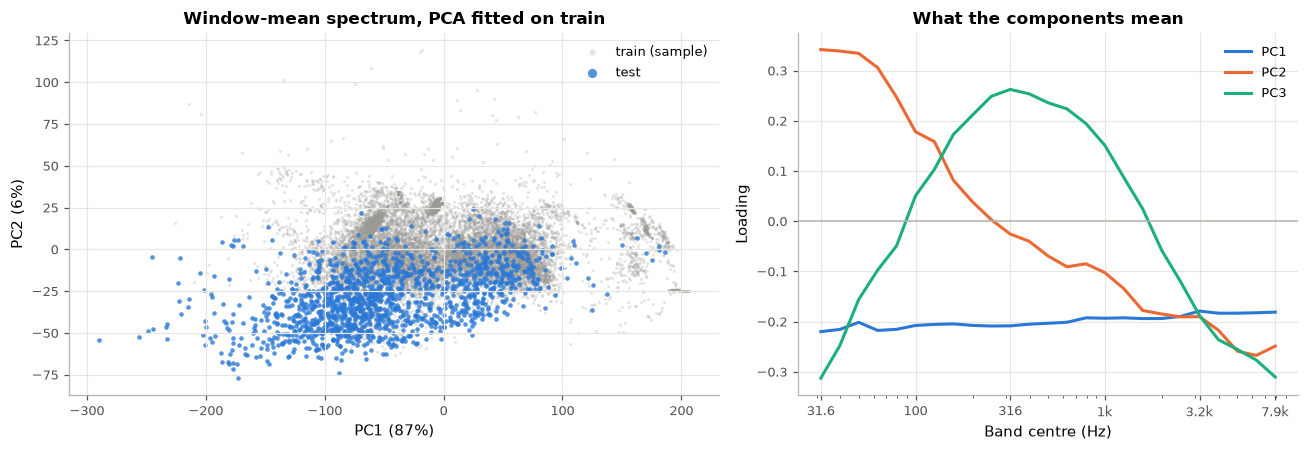

In [16]:
def window_mean_spectrum(X):
    return lin_to_db(np.nanmean(db_to_lin(X), axis=1))   # (windows, 25)

S_train = window_mean_spectrum(X_train)
S_test = window_mean_spectrum(X_test)

mu = S_train.mean(axis=0)
U, sv, Vt = np.linalg.svd(S_train - mu, full_matrices=False)
explained = sv ** 2 / (sv ** 2).sum()
P_train = (S_train - mu) @ Vt[:2].T
P_test = (S_test - mu) @ Vt[:2].T

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
sub = rng.choice(len(P_train), 15000, replace=False)
ax.scatter(P_train[sub, 0], P_train[sub, 1], s=4, color=GRAY, alpha=0.25, linewidths=0, label="train (sample)")
ax.scatter(P_test[:, 0], P_test[:, 1], s=9, color=SERIES[0], alpha=0.8, linewidths=0, label="test")
ax.set_xlabel(f"PC1 ({explained[0]:.0%})"); ax.set_ylabel(f"PC2 ({explained[1]:.0%})")
ax.set_title("Window-mean spectrum, PCA fitted on train"); ax.legend(loc="upper right", markerscale=2)

ax = axes[1]
for i in range(3):
    ax.plot(FREQ, Vt[i], color=SERIES[i], label=f"PC{i + 1}")
ax.axhline(0, color="#b5b4ae", lw=1)
freq_axis(ax); ax.set_ylabel("Loading"); ax.set_title("What the components mean"); ax.legend()
plt.tight_layout(); plt.show()

In [17]:
# Nearest training station for each test window (by centroid in the 25-band mean-spectrum space)
cent = pd.DataFrame(S_train).groupby(win_meta["site_name"].values).median()
dist = ((S_test[:, None, :] - cent.values[None]) ** 2).sum(axis=2) ** 0.5
nearest = pd.Series(cent.index[dist.argmin(axis=1)]).value_counts()
pd.DataFrame({"test windows nearest": nearest,
              "share of train windows (%)": win_meta["site_name"].value_counts(normalize=True).mul(100).round(1)}
            ).fillna(0).sort_values("test windows nearest", ascending=False)

,test windows nearest,share of train windows (%)
St Francis,770,3.8
Fish Hoek,189,0.3
Bird Island,141,3.6
St Croix Island,140,19.0
Saldhana Bay,128,10.1
Durban,75,3.4
Sea Point,50,0.3
Richards Bay,7,59.6


**Interpret with care.** Test windows sit nearest to **St Francis** far more often than any other station, and
almost never nearest to Richards Bay, even though Richards Bay makes up 60% of training windows. Part of this
is the added vessel energy raising and flattening the spectrum (St Francis is the loudest station). The test
backgrounds may also come from withheld periods or stations. Either way, the station mix in the test set
clearly differs from the raw training mix, so **per-site balancing matters**, and St Francis is badly
under-represented in the windows because of its duty cycle.

## 7. Within-window dynamics

A vessel passage rises and falls over minutes, while ambient noise is usually steadier. If the controlled
addition is visible, test windows should show **more minute-to-minute change** than the real backgrounds.
Measures used:
- **range**: max − min of the per-minute broadband level within the window (dB)
- **peakiness**: peak minute minus the window median (dB)
- **low-frequency share change**: range of the 50–500 Hz share of energy (vessel noise concentrates at low frequency)

In [18]:
def dynamics(X):
    bb = broadband_db(X)                                     # (windows, 15), NaN for missing minutes
    lin = db_to_lin(X)
    lo = (FREQ >= 50) & (FREQ <= 500)
    lo_share = lin[..., lo].sum(-1) / lin.sum(-1)
    return pd.DataFrame({
        "broadband_mean_db": lin_to_db(np.nanmean(db_to_lin(bb), axis=1)),
        "range_db": np.nanmax(bb, 1) - np.nanmin(bb, 1),
        "peakiness_db": np.nanmax(bb, 1) - np.nanmedian(bb, 1),
        "lowfreq_share_range": np.nanmax(lo_share, 1) - np.nanmin(lo_share, 1),
    })

D_train = dynamics(X_train)
D_test = dynamics(X_test)
pd.concat({"train": D_train.describe(percentiles=[.1, .5, .9]).T,
           "test": D_test.describe(percentiles=[.1, .5, .9]).T}, axis=0)[["mean", "10%", "50%", "90%"]].round(2)

mean    10%     50%     90%
train broadband_mean_db     97.27  78.73   98.87  115.73
      range_db              11.40   2.15    7.25   29.38
      peakiness_db           8.27   1.06    4.18   25.48
      lowfreq_share_range    0.31   0.09    0.28    0.57
test  broadband_mean_db    101.78  83.59  103.21  117.83
      range_db              13.01   4.82   12.48   21.51
      peakiness_db           8.34   2.71    7.93   14.24
      lowfreq_share_range    0.41   0.18    0.40    0.64

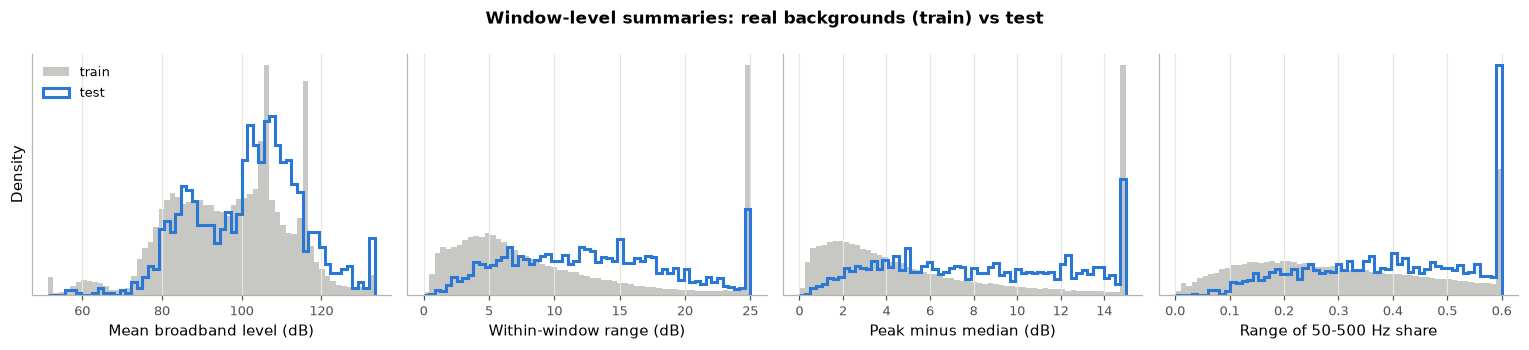

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
specs = [("broadband_mean_db", "Mean broadband level (dB)", None),
         ("range_db", "Within-window range (dB)", (0, 25)),
         ("peakiness_db", "Peak minus median (dB)", (0, 15)),
         ("lowfreq_share_range", "Range of 50-500 Hz share", (0, 0.6))]
for ax, (col, label, lim) in zip(axes, specs):
    a, b = D_train[col].dropna(), D_test[col].dropna()
    lo_, hi_ = lim if lim else (np.percentile(pd.concat([a, b]), [0.5, 99.5]))
    bins = np.linspace(lo_, hi_, 60)
    ax.hist(a.clip(lo_, hi_), bins=bins, density=True, color=GRAY, alpha=0.55, edgecolor="none", label="train")
    ax.hist(b.clip(lo_, hi_), bins=bins, density=True, histtype="step", color=SERIES[0], lw=2, label="test")
    ax.set_xlabel(label); ax.set_yticks([])
axes[0].set_ylabel("Density"); axes[0].legend()
fig.suptitle("Window-level summaries: real backgrounds (train) vs test", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

Values beyond each axis limit are piled into the last bin, which causes the spikes at the right edge.

**Reading it:** test windows are louder (median about +4 dB) and much less often "flat". Within-window range
and peakiness move away from the 0–5 dB area where most real backgrounds sit. But real backgrounds also have
a long tail of large swings (natural vessels, weather, biology), so dynamics alone won't separate the classes.
That matches the warning that "real backgrounds can already contain vessels".

### 7a. Example windows

Spectrograms (minute × band) for a few test windows with the largest and smallest within-window range. The
color scale is set per panel because the absolute level varies from window to window.

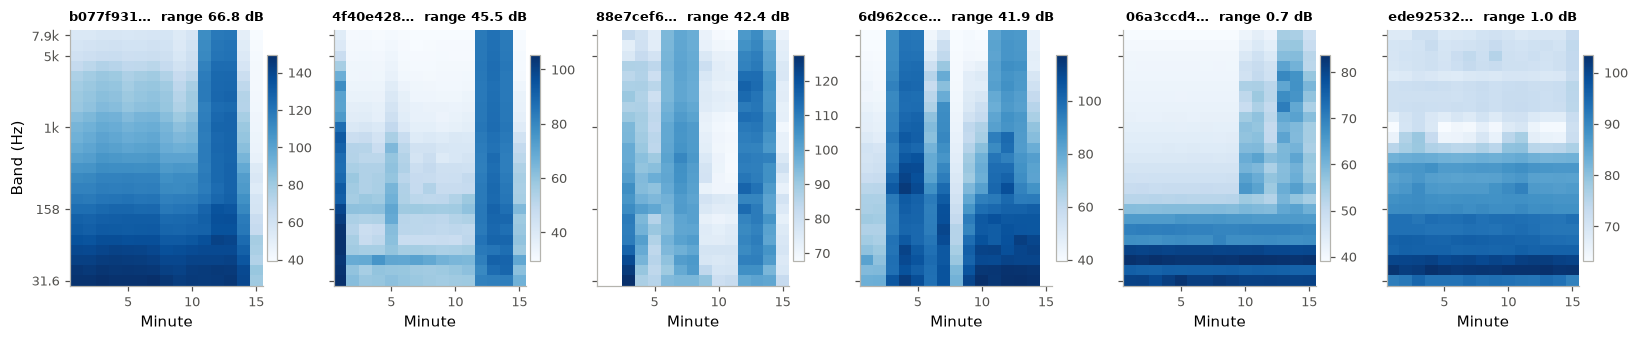

In [20]:
order = D_test["range_db"].sort_values()
pick = list(order.index[-4:][::-1]) + list(order.index[:2])
fig, axes = plt.subplots(1, len(pick), figsize=(15, 3.2), sharey=True)
for ax, i in zip(axes, pick):
    im = ax.imshow(X_test[i].T, origin="lower", aspect="auto", cmap="Blues",
                   extent=[0.5, 15.5, -0.5, 24.5])
    ax.set_title(f"{test['ID'][i][:8]}…  range {D_test['range_db'][i]:.1f} dB", fontsize=8.5)
    ax.set_xlabel("Minute"); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02)
axes[0].set_yticks([0, 7, 15, 22, 24]); axes[0].set_yticklabels(["31.6", "158", "1k", "5k", "7.9k"])
axes[0].set_ylabel("Band (Hz)")
plt.tight_layout(); plt.show()

## 8. Diurnal and band-correlation structure (training)

Hour-of-day deviation of the broadband level from each station's median. The export clock's timezone is
unverified, so treat hours as approximate. Strong daily cycles (snapping shrimp, fish choruses, harbour
activity) are a source of ambient variation that a model must not mistake for vessels.

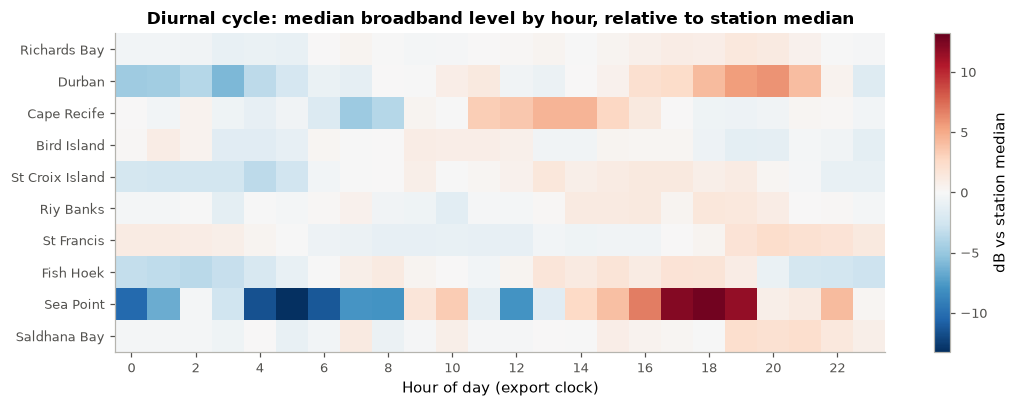

In [21]:
bb_min = broadband_db(levels)
hour = clean["t"].dt.hour.values
tab = (pd.DataFrame({"site": clean["site_name"].values, "hour": hour, "bb": bb_min})
         .dropna().groupby(["site", "hour"])["bb"].median().unstack())
dev = tab.sub(tab.median(axis=1), axis=0)
dev = dev.loc[clean.groupby("site_name")["site_id"].first().sort_values().index]

lim = np.nanmax(np.abs(dev.values))
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(dev.values, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_yticks(range(len(dev))); ax.set_yticklabels(dev.index)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour of day (export clock)")
ax.grid(False)
fig.colorbar(im, ax=ax, label="dB vs station median")
ax.set_title("Diurnal cycle: median broadband level by hour, relative to station median")
plt.tight_layout(); plt.show()

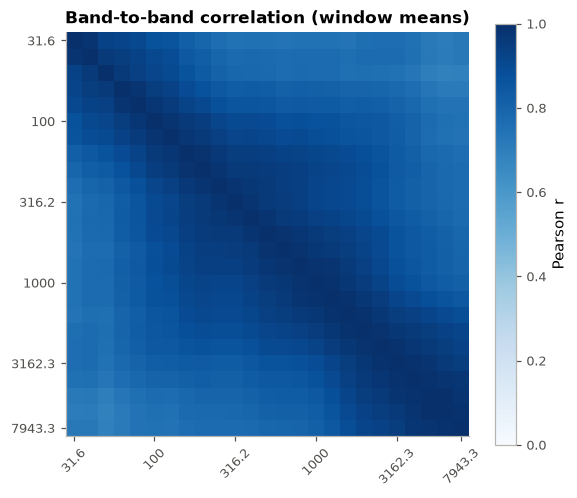

Variance explained by first 3 PCs: [0.869 0.061 0.038]


In [22]:
corr = np.corrcoef(S_train[rng.choice(len(S_train), 20000, replace=False)].T)
fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
tick = [0, 5, 10, 15, 20, 24]
ax.set_xticks(tick); ax.set_xticklabels([BANDS[i] for i in tick], rotation=45)
ax.set_yticks(tick); ax.set_yticklabels([BANDS[i] for i in tick])
ax.grid(False); fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Band-to-band correlation (window means)")
plt.tight_layout(); plt.show()
print("Variance explained by first 3 PCs:", np.round(explained[:3], 3))

## 9. Takeaways for modelling

**Cleaning**
1. Treat −156.5 dB (and any negative level) as missing. It only appears at Richards Bay (654 rows).
2. Drop minutes shorter than 55 s, and only build windows from consecutive minutes (99% of minutes are usable).
3. Group by `deployment` (site + recorder), not by site name. Recorders moved between sites, so
   cross-validation should use `GroupKFold` on site or deployment to avoid leaking a background between folds.
4. Richards Bay is 58% of minutes and 60% of windows, yet test windows rarely resemble it. Reweight or
   subsample by site.
5. Duty cycling leaves Cape Recife and Riy Banks with no 15-minute windows, and St Francis and Fish Hoek with
   very few. Decide whether to build partial windows from them.

**Building synthetic training data**

The real backgrounds are unlabelled, and the target (`share_added_vessel`) describes a *controlled addition*.
Training labels therefore have to come from mixing a vessel-passage component into these backgrounds
**in linear energy**:

    mix_lin = bg_lin + vessel_lin
    share   = vessel_lin.sum() / mix_lin.sum()

The passage components can come from the permitted external data (VTUAD / ONC), using the `minute_band_power`
helper in the starter notebook. To match the test set, blank one whole minute (mostly minute 1, sometimes 15)
at the observed rates.

**Features that look promising**
- Within-window dynamics (range, peakiness, change in the low-frequency share), compared in section 7
- The window spectrum relative to the station-typical spectrum. A nearest-station estimate from the spectrum
  helps because test rows carry no site label.
- Use NaN-aware statistics so the missing minute doesn't distort features.